In [10]:
# Loading the data
import pandas as pd
df = pd.read_csv("city_day.csv")
df.shape

(29531, 16)

In [11]:
import matplotlib.pyplot as plt

In [12]:
# Keep only Delhi
delhi = df[df["City"] == "Delhi"].copy()

# Get the month number (1-12)
delhi["month"] = pd.to_datetime(delhi["Date"]).dt.month

monthly = delhi.groupby("month")["AQI"].mean()
print(monthly)

month
1     360.387097
2     298.829412
3     222.623656
4     248.444444
5     258.693548
6     199.418994
7     137.574194
8     134.442177
9     157.426667
10    312.329032
11    401.953333
12    371.206452
Name: AQI, dtype: float64


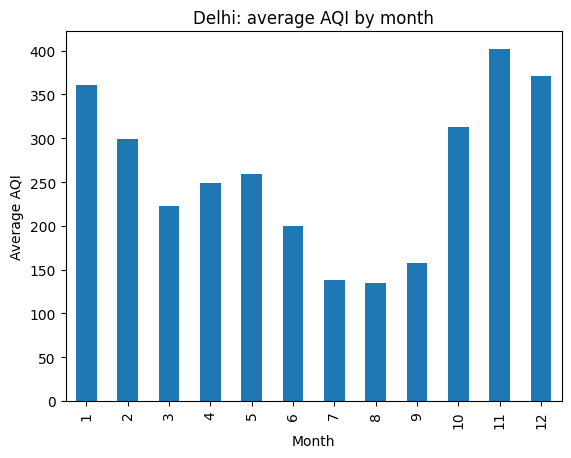

In [13]:
# Delhi average AQI by month
monthly.plot(kind="bar")
plt.title("Delhi: average AQI by month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.show()

In [14]:
# List of columns
delhi.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'month'],
      dtype='object')

In [15]:
# Shortlisting the columns for training
keep = ['Benzene', 'Toluene', 'Xylene', 'month', 'AQI']
data = delhi[keep].dropna()
len(data)

1228

In [16]:
# Training the model
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

X = data[['Benzene', 'Toluene', 'Xylene', 'month']]
y = data['AQI']

train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=0)

AQI_model = DecisionTreeRegressor(random_state=0)
AQI_model.fit(train_X, train_y)
val_predictions = AQI_model.predict(val_X)
print("Predictions:", AQI_model.predict(val_X.head()))
print("Actuals:", val_y.head())

Predictions: [403.  90. 377. 114.  89.]
Actuals: 10247    362.0
11556    138.0
11278    378.0
12231     86.0
11884    243.0
Name: AQI, dtype: float64


In [17]:
# Mean absolute error
val_predictions = AQI_model.predict(val_X)

print("Model MAE:", mean_absolute_error(val_y, val_predictions))

Model MAE: 55.4071661237785


In [18]:
# Baseline
baseline = [train_y.median()] * len(val_y)
print("Baseline MAE:", mean_absolute_error(val_y, baseline))

Baseline MAE: 96.19543973941369


Goal: Use machine learning to check if the model could estimate Delhi's AQI by training it on same-day pollutants data from 2015-2020.


Data: https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india
License: CC0: Public Domain, per the Kaggle dataset page.

The data has been made publicly available by the Central Pollution Control Board: https://cpcb.nic.in/ which is the official portal of Government of India. They also have a real-time monitoring app: https://app.cpcbccr.com/AQI_India/


Note: The Delhi subset contains 1,228 rows of Delhi air quality data after removing missing values.


**Approach and Results:**

*   For this analysis, I decided to train the model on the following pollutants: benzene, toluene, xylene, along with the month, to check whether it could estimate the AQI. I left out other pollutants, which could be used to calculate the AQI, from the training data to prevent the model from calculating it directly.

*   I used a bar chart to graphically represent the mean AQI trend across the 12 months, which showed the highest average to be in the months of November and December. The lowest months were July and August (monsoon season).

*   The model's average error was 55 points, compared to the baseline average error of 96 points (the baseline guesses the median AQI for every day).

**What I Learned:**

*   I had initially used a different dataset for calculation, it suspiciously showed an average error of 0.0026, which meant that the model was estimating the AQI by calculating it using the pollutants data rather than looking at the pattern, or "data leakage". This is when I realized that the dataset and training inputs need to be changed.

**Limitations:**

*   The dataset is small with the analysis focused only on the city of Delhi.

*   This model serves to estimate the AQI, rather than forecast it.

*  While cleaning the missing values, the data was cut down from 2,009 to 1,228.

**Acknowledgements:**

I learned Python, pandas and scikit-learn for this project with guidance from Claude (Anthropic's AI assistant), which acted as a tutor and explained concepts, helped with the code, answered questions, and helped me interpret the results. I made the modelling decisions and wrote the findings.

